# 01 — Toronto study area

## Purpose

This notebook defines the spatial domain for the Toronto v2 heat-conditioned accessibility experiment.

The study area is designed as an **8 km × 8 km square centered on the University of Toronto St. George campus**.

The notebook will:

1. geocode the University of Toronto St. George campus;
2. project the campus location to a metric coordinate reference system;
3. construct an exact 8 km × 8 km square;
4. download the pedestrian network inside the square;
5. retrieve a small amount of OSM context for visual inspection;
6. validate the study-area dimensions;
7. save the study-area polygon, center point, and walking network for later notebooks.

This notebook should be run with:

**Python 3.12 - VoxCity**

## 1. Imports and project paths

Toronto-specific data are stored separately from the Sevilla proof-of-concept.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import osmnx as ox
import pandas as pd

from shapely.geometry import box

HERE = Path.cwd().resolve()

if HERE.name == "notebooks_toronto_v02":
    PROJECT_ROOT = HERE.parent
elif (HERE / "notebooks_toronto_v02").exists():
    PROJECT_ROOT = HERE
else:
    PROJECT_ROOT = Path(
        "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
    )

TORONTO_DATA = PROJECT_ROOT / "data" / "toronto"
TORONTO_RAW = TORONTO_DATA / "raw"
TORONTO_INTERIM = TORONTO_DATA / "interim"
TORONTO_OUTPUTS = PROJECT_ROOT / "outputs" / "toronto"

for folder in [
    TORONTO_RAW,
    TORONTO_INTERIM,
    TORONTO_OUTPUTS,
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Toronto raw data:", TORONTO_RAW)

Project root: /scratch/project_2010417/paper3/heat-conditioned-accessibility
Toronto raw data: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/raw


## 2. Geocode the University of Toronto St. George campus

The study-area center is obtained through OSM/Nominatim geocoding rather than hard-coded coordinates.

We first try the full campus name. A fallback query is included in case the first query does not resolve in the current OSM geocoder.

In [2]:
primary_query = "University of Toronto St. George Campus, Toronto, Ontario, Canada"
fallback_query = "University of Toronto, Toronto, Ontario, Canada"

try:
    campus = ox.geocode_to_gdf(primary_query)
    geocoded_query = primary_query
except Exception:
    campus = ox.geocode_to_gdf(fallback_query)
    geocoded_query = fallback_query

print("Geocoded query:", geocoded_query)
print("CRS:", campus.crs)

display(
    campus[
        [column for column in ["display_name", "geometry"] if column in campus.columns]
    ].head()
)

Geocoded query: University of Toronto, Toronto, Ontario, Canada
CRS: epsg:4326


,display_name,geometry
0,"University of Toronto St. George, College Stre...","MULTIPOLYGON (((-79.40658 43.66972, -79.40645 ..."


## 3. Derive a single campus center point

Geocoding may return a polygon or multipolygon rather than a point.

We therefore calculate the centroid in a projected coordinate system so that the center is spatially meaningful in metres.

In [3]:
# Toronto lies in UTM Zone 17N.
TARGET_CRS = "EPSG:32617"

campus_projected = campus.to_crs(TARGET_CRS)

campus_center_geometry = campus_projected.geometry.centroid.iloc[0]

campus_center = gpd.GeoDataFrame(
    {
        "name": ["University of Toronto St. George"],
    },
    geometry=[campus_center_geometry],
    crs=TARGET_CRS,
)

print("Projected CRS:", campus_center.crs)
print("Campus center:")
print(
    "Easting:",
    round(campus_center.geometry.x.iloc[0], 2),
    "Northing:",
    round(campus_center.geometry.y.iloc[0], 2),
)

Projected CRS: EPSG:32617
Campus center:
Easting: 629323.61 Northing: 4835772.97


## 4. Construct an exact 8 km × 8 km study square

A square of 8 km × 8 km has an area of:

\[
8 \times 8 = 64\;\text{km}^2
\]

The square is constructed as ±4 km from the campus center in both projected x and y directions.

In [4]:
HALF_WIDTH_M = 4000
EXPECTED_WIDTH_M = 8000
EXPECTED_AREA_KM2 = 64

x = campus_center.geometry.x.iloc[0]
y = campus_center.geometry.y.iloc[0]

study_square_geom = box(
    x - HALF_WIDTH_M,
    y - HALF_WIDTH_M,
    x + HALF_WIDTH_M,
    y + HALF_WIDTH_M,
)

study_area = gpd.GeoDataFrame(
    {
        "name": ["Toronto UofT 8 km x 8 km study area"],
    },
    geometry=[study_square_geom],
    crs=TARGET_CRS,
)

study_area

,name,geometry
0,Toronto UofT 8 km x 8 km study area,"POLYGON ((633323.607 4831772.969, 633323.607 4..."


## 5. Validate the dimensions

This check confirms that reprojection and construction produced the intended extent.

In [5]:
xmin, ymin, xmax, ymax = study_area.total_bounds

width_m = xmax - xmin
height_m = ymax - ymin
area_km2 = study_area.geometry.area.iloc[0] / 1_000_000

validation = pd.DataFrame(
    {
        "metric": [
            "Width",
            "Height",
            "Area",
        ],
        "value": [
            width_m,
            height_m,
            area_km2,
        ],
        "expected": [
            8000,
            8000,
            64,
        ],
        "unit": [
            "m",
            "m",
            "km²",
        ],
    }
)

display(validation)

assert np.isclose(width_m, 8000)
assert np.isclose(height_m, 8000)
assert np.isclose(area_km2, 64)

print("✓ Study area dimensions validated.")

,metric,value,expected,unit
0,Width,8000.0,8000,m
1,Height,8000.0,8000,m
2,Area,64.0,64,km²


✓ Study area dimensions validated.


## 6. Convert the study polygon to WGS84 for OSM queries

OSMnx expects geographic coordinates for polygon-based downloads.

In [6]:
study_area_wgs84 = study_area.to_crs(4326)
campus_center_wgs84 = campus_center.to_crs(4326)

print("Study area WGS84 bounds:")
print(study_area_wgs84.total_bounds)

print("\nCampus center WGS84:")
print(
    round(campus_center_wgs84.geometry.x.iloc[0], 6),
    round(campus_center_wgs84.geometry.y.iloc[0], 6),
)

Study area WGS84 bounds:
[-79.44652941  43.62700227 -79.34542662  43.70039839]

Campus center WGS84:
-79.396008 43.66371


## 7. Download the walking network inside the study square

The network is downloaded with `network_type="walk"` so that pedestrian-accessible streets and paths are included.

`truncate_by_edge=True` helps retain edges that cross the study-area boundary.

In [8]:
import time
import osmnx as ox

study_polygon_wgs84 = study_area_wgs84.geometry.iloc[0]

# Public Overpass endpoints to try.
overpass_endpoints = [
    "https://overpass-api.de/api",
    "https://lz4.overpass-api.de/api",
    "https://z.overpass-api.de/api",
]

G_walk = None
last_error = None

for endpoint in overpass_endpoints:

    print(f"\nTrying Overpass endpoint: {endpoint}")

    # OSMnx appends /interpreter internally.
    ox.settings.overpass_url = endpoint

    for attempt in range(1, 4):

        try:
            print(f"Attempt {attempt}/3")

            G_walk = ox.graph_from_polygon(
                study_polygon_wgs84,
                network_type="walk",
                simplify=True,
                retain_all=True,
                truncate_by_edge=True,
            )

            print("✓ Walking network downloaded successfully.")
            break

        except Exception as exc:
            last_error = exc

            print(
                f"Attempt {attempt} failed:",
                type(exc).__name__,
                str(exc)[:300],
            )

            if attempt < 3:
                pause = 15 * (2 ** (attempt - 1))
                print(f"Waiting {pause} seconds before retrying...")
                time.sleep(pause)

    if G_walk is not None:
        break


if G_walk is None:
    raise RuntimeError(
        "Walking-network download failed on all configured "
        "Overpass endpoints."
    ) from last_error


print("\nFinal walking network")
print("---------------------")
print("Nodes:", G_walk.number_of_nodes())
print("Edges:", G_walk.number_of_edges())


Trying Overpass endpoint: https://overpass-api.de/api
Attempt 1/3
Attempt 1 failed: ResponseStatusCodeError 'overpass-api.de' responded: 502 Bad Gateway # 502 Gateway Timeout

This Overpass API server is currently at capacity. All query workers are busy
and the request queue is full.

## What to do

Retry your request using exponential backoff: wait a short interval, then retry.
If the request fails again
Waiting 15 seconds before retrying...
Attempt 2/3
✓ Walking network downloaded successfully.

Final walking network
---------------------
Nodes: 35817
Edges: 96924


## 8. Project the walking network

The network is projected to the same Toronto UTM CRS used for the study-area square.

Keeping all spatial layers in a common projected CRS simplifies later distance, raster, and accessibility calculations.

In [9]:
G_walk_projected = ox.project_graph(
    G_walk,
    to_crs=TARGET_CRS,
)

nodes_walk, edges_walk = ox.graph_to_gdfs(
    G_walk_projected
)

print("Projected network CRS:", edges_walk.crs)

Projected network CRS: EPSG:32617


## 9. Retrieve lightweight OSM context

These layers are used only to inspect what the 8 km × 8 km domain contains.

We retrieve:

- building footprints;
- parks/green-space features;
- rail/transit features where available.

More detailed urban-form inputs will be assembled in later notebooks.

In [10]:
context_tags = {
    "building": True,
    "leisure": ["park", "garden"],
    "landuse": ["grass", "recreation_ground"],
}

context = ox.features_from_polygon(
    study_polygon_wgs84,
    tags=context_tags,
)

context = context.reset_index()

print("OSM context features:", len(context))
print(
    context.geometry.geom_type.value_counts()
)

OSM context features: 66784
Polygon         66717
Point              46
MultiPolygon       21
Name: count, dtype: int64


## 10. Separate context layers for plotting

This is only for visualization. The later VoxCity notebook will build the actual urban-form inputs.

In [11]:
context_projected = context.to_crs(TARGET_CRS)

building_context = context_projected[
    context_projected.get(
        "building",
        pd.Series(index=context_projected.index, dtype=object),
    ).notna()
].copy()

green_context = context_projected[
    (
        context_projected.get(
            "leisure",
            pd.Series(index=context_projected.index, dtype=object),
        ).isin(["park", "garden"])
    )
    |
    (
        context_projected.get(
            "landuse",
            pd.Series(index=context_projected.index, dtype=object),
        ).isin(["grass", "recreation_ground"])
    )
].copy()

print("Building-context features:", len(building_context))
print("Green-space features:", len(green_context))

Building-context features: 60997
Green-space features: 5787


## 11. Visualize the 8 km × 8 km study area

This figure is the main spatial sanity check.

We want to verify that:

- the University of Toronto lies near the center;
- the study area captures a diverse part of central Toronto;
- the walking network is sufficiently complete;
- the extent is reasonable for the intended thermal experiment.

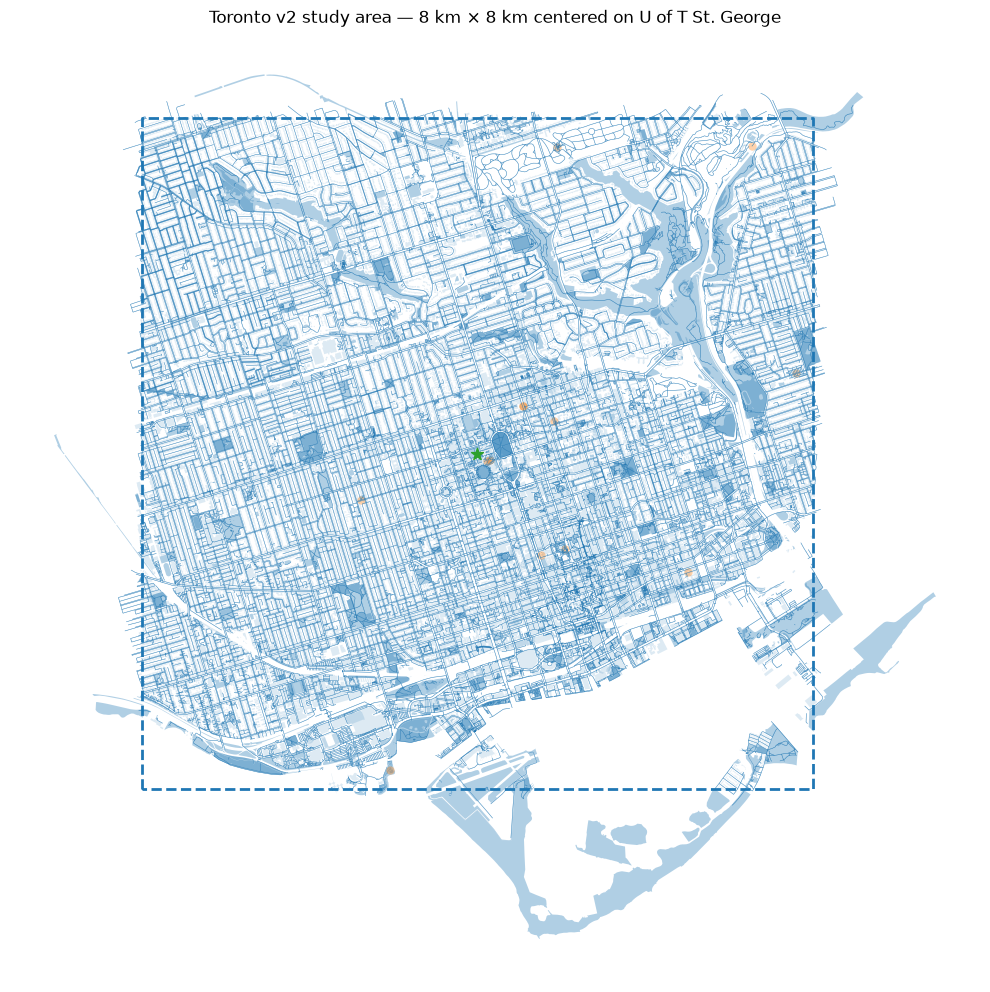

In [12]:
fig, ax = plt.subplots(figsize=(10, 10))

if len(building_context):
    building_context.plot(
        ax=ax,
        alpha=0.15,
        linewidth=0,
    )

if len(green_context):
    green_context.plot(
        ax=ax,
        alpha=0.35,
        linewidth=0,
    )

edges_walk.plot(
    ax=ax,
    linewidth=0.35,
    alpha=0.55,
)

study_area.boundary.plot(
    ax=ax,
    linewidth=2.0,
    linestyle="--",
)

campus_center.plot(
    ax=ax,
    markersize=80,
    marker="*",
    zorder=10,
)

ax.set_title(
    "Toronto v2 study area — 8 km × 8 km centered on U of T St. George"
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

## 12. Inspect the position of the campus within the study square

The distances from the campus center to each study-area edge should be approximately 4 km.

In [13]:
center_x = campus_center.geometry.x.iloc[0]
center_y = campus_center.geometry.y.iloc[0]

distances = {
    "west_m": center_x - xmin,
    "east_m": xmax - center_x,
    "south_m": center_y - ymin,
    "north_m": ymax - center_y,
}

display(
    pd.DataFrame(
        {
            "direction": distances.keys(),
            "distance_m": distances.values(),
        }
    )
)

,direction,distance_m
0,west_m,4000.0
1,east_m,4000.0
2,south_m,4000.0
3,north_m,4000.0


## 13. Save study-area outputs

These files become the spatial reference for all later Toronto notebooks.

Saved outputs:

- `toronto_uoft_center.gpkg`
- `toronto_study_area_8km.gpkg`
- `toronto_walk_8km.graphml`

In [14]:
campus_center.to_file(
    TORONTO_RAW / "toronto_uoft_center.gpkg",
    driver="GPKG",
)

study_area.to_file(
    TORONTO_RAW / "toronto_study_area_8km.gpkg",
    driver="GPKG",
)

ox.save_graphml(
    G_walk_projected,
    filepath=TORONTO_RAW / "toronto_walk_8km.graphml",
)

print("Saved:")
print("-", TORONTO_RAW / "toronto_uoft_center.gpkg")
print("-", TORONTO_RAW / "toronto_study_area_8km.gpkg")
print("-", TORONTO_RAW / "toronto_walk_8km.graphml")

Saved:
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/raw/toronto_uoft_center.gpkg
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/raw/toronto_study_area_8km.gpkg
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/raw/toronto_walk_8km.graphml


## 14. Final study-area summary

In [15]:
summary = {
    "study_area_width_km": width_m / 1000,
    "study_area_height_km": height_m / 1000,
    "study_area_km2": area_km2,
    "walking_nodes": G_walk_projected.number_of_nodes(),
    "walking_edges": G_walk_projected.number_of_edges(),
    "projected_crs": TARGET_CRS,
}

for key, value in summary.items():
    print(f"{key}: {value}")

study_area_width_km: 8.0
study_area_height_km: 8.0
study_area_km2: 64.0
walking_nodes: 35817
walking_edges: 96924
projected_crs: EPSG:32617


## Interpretation and next step

This notebook establishes the spatial framework for Toronto v2.

The study domain is deliberately much larger than the Sevilla thermal proof-of-concept. At **64 km²**, the Toronto domain should capture greater variation in:

- urban density;
- building form;
- street-network structure;
- vegetation and park access;
- thermal exposure;
- transit accessibility.

Before thermal simulation, however, the next task is to characterize the urban form and determine which datasets should be used for:

- building footprints;
- building height;
- vegetation/canopy;
- land cover;
- terrain.

Continue to:

**`02_toronto_urban_form_inputs.ipynb`**